# Laboratorio 2, de redes densas a CNNs
MNIST y Fashion MNIST, el caso a favor de las convoluciones.

Pregunta guia del lab: una brecha de desempeno es por la arquitectura o por la dificultad de la tarea. Partes 1 y 2 dejan fija la arquitectura y cambian la tarea. Parte 3 deja fija la tarea y cambia la arquitectura.

## Parte 0, imports y semilla

torch.manual_seed(42) fijo una sola vez al inicio, antes de armar cualquier modelo. nn.Linear y nn.Conv2d inicializan pesos random en el momento que se crean. Si no fijamos la semilla antes de crear DenseNet, DenseNet de nuevo para fashion y ConvNet, cada corrida arranca de un punto distinto y ya no se puede saber si el cambio de accuracy es por la arquitectura, por la tarea o solo por azar de inicializacion.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

from dotenv import load_dotenv
import os

RANDOM_SEED = 42
torch.manual_seed(RANDOM_SEED)

## Parte 1.1, cargando MNIST

Codigo dado por el PDF, no es TAREA. load_dotenv lee el .env de la carpeta y expone MNIST_TRAIN_FILEPATH y MNIST_TEST_FILEPATH via os.getenv. Cada npz es un diccionario con dos llaves, images con forma (N, 28, 28) de enteros 0 a 255 y labels con forma (N,) de enteros 0 a 9.

In [2]:
load_dotenv('.env')

mnist_train_fp = os.getenv('MNIST_TRAIN_FILEPATH')
mnist_test_fp = os.getenv('MNIST_TEST_FILEPATH')

mnist_train = np.load(mnist_train_fp)
mnist_test = np.load(mnist_test_fp)

print(f"Train dataset file path: {mnist_train_fp}")
print(f"Test dataset file path: {mnist_test_fp}")
print(f"mnist_train images shape: {mnist_train['images'].shape}, labels shape: {mnist_train['labels'].shape}")
print(f"mnist_test images shape: {mnist_test['images'].shape}, labels shape: {mnist_test['labels'].shape}")

Train dataset file path: mnist_dataset/mnist_train.npz
Test dataset file path: mnist_dataset/mnist_test.npz
mnist_train images shape: (60000, 28, 28), labels shape: (60000,)
mnist_test images shape: (10000, 28, 28), labels shape: (10000,)


## TAREA 1.2, divide y escala MNIST

Ya tenemos el test oficial, mnist_test, cargado arriba. Aca solo partimos mnist_train en train y val. No hace falta sacar otro test de ahi, eso solo aplicaba en el lab de cancer porque ahi no venia un test separado de fabrica.

In [3]:
# mnist_train viene como imagenes (N,28,28) mas labels, aplano las imagenes a 784 porque eso recibe la DenseNet
x = mnist_train['images'].reshape(-1, 28 * 28)
y = mnist_train['labels']

# no saco un test nuevo aca, el test ya esta en mnist_test, cargado en 1.1
# separo train y val nomas, con stratify para que cada digito quede repartido parejo en los dos
x_train, x_val, y_train, y_val = train_test_split(
    x, y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_SEED
)

print(f"x_train shape: {x_train.shape}")
print(f"x_val shape: {x_val.shape}")

x_train shape: (48000, 784)
x_val shape: (12000, 784)


In [4]:
# el pdf pide NO usar StandardScaler aca, con dividir entre 255 ya alcanza
# los pixeles ya estan en el mismo rango fijo y conocido, 0 a 255, no como las features de cancer que tenian escalas bien distintas entre si
x_train_scaled = x_train / 255.0
x_val_scaled = x_val / 255.0

# el test no sale de x, eso es train, sale de mnist_test que cargue en 1.1 y todavia no lo habia aplanado
x_test = mnist_test['images'].reshape(-1, 28 * 28)
y_test = mnist_test['labels']
x_test_scaled = x_test / 255.0

print(f"x_train_scaled min/max: {x_train_scaled.min()}, {x_train_scaled.max()}")
print(f"x_test_scaled min/max: {x_test_scaled.min()}, {x_test_scaled.max()}")

x_train_scaled min/max: 0.0, 1.0
x_test_scaled min/max: 0.0, 1.0


### Tensores de PyTorch

X pasa a FloatTensor y y pasa a LongTensor de indices de clase, 0 a 9. Sin unsqueeze, sin one hot. CrossEntropyLoss pide justo eso, un entero por muestra con la clase correcta, y adentro compara sola contra los 10 logits.

In [5]:
X_train_t = torch.from_numpy(x_train_scaled).float()
X_val_t = torch.from_numpy(x_val_scaled).float()
X_test_t = torch.from_numpy(x_test_scaled).float()

y_train_t = torch.from_numpy(y_train).long()
y_val_t = torch.from_numpy(y_val).long()
y_test_t = torch.from_numpy(y_test).long()

print(f"X_train_t: {tuple(X_train_t.shape)}, dtype={X_train_t.dtype}")
print(f"y_train_t: {tuple(y_train_t.shape)}, dtype={y_train_t.dtype}")

BATCH_SIZE = 128

train_dataset = TensorDataset(X_train_t, y_train_t)
dataloader_generator = torch.Generator().manual_seed(RANDOM_SEED)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=dataloader_generator,
)

X_train_t: (48000, 784), dtype=torch.float32
y_train_t: (48000,), dtype=torch.int64


## 1.3 arquitectura, dada por el PDF

Entrada, 784 features, la imagen 28x28 aplanada. Capa 1, Linear de 784 a 128, seguida de ReLU. Capa 2, Linear de 128 a 10, logits crudos, sin activacion.

MNIST tiene 10 clases, entonces necesitamos 10 salidas, una por clase. No metemos Softmax adentro del modelo porque CrossEntropyLoss ya espera logits crudos y aplica un equivalente de softmax combinado con la perdida adentro, en una sola operacion mas estable numericamente que aplicar Softmax aparte.

## TAREA 1.4, DenseNet, construir, entrenar, evaluar

Armo la clase DenseNet tal cual la pide el PDF, Linear 784 a 128, ReLU, Linear 128 a 10, logits crudos. Como en las Partes 2, 3 y 4 vamos a repetir el mismo procedimiento de entrenamiento, misma funcion de perdida, mismo optimizador, mismo patron de ciclo por epoca, sobre modelos y datos distintos, lo paso a funciones reutilizables, train_classifier y evaluate_accuracy, en vez de copiar el bucle 4 veces. Es una decision mia, no algo que pida el PDF. Lo bueno es que asi no se puede colar un hiperparametro distinto entre MNIST y Fashion por copiar y pegar mal, que es justo lo que la comparacion Parte 1 contra Parte 2 necesita para valer.

In [6]:
class DenseNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(784, 128)
        self.layer2 = nn.Linear(128, 10)

    def forward(self, x):
        output = F.relu(self.layer1(x))  # activacion en la oculta
        output = self.layer2(output)     # logits crudos, sin activacion, CrossEntropyLoss los pide asi
        return output

In [7]:
EPOCHS = 10
LEARNING_RATE = 1e-3


def train_classifier(model, loader, X_val, y_val, epochs=EPOCHS, lr=LEARNING_RATE):
    """Mismo patron de entrenamiento del notebook de cancer de mama, adaptado a clasificacion multiclase."""
    loss_fn = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    train_loss_history = []
    val_loss_history = []

    print(f"{'Epoch':>5s} | {'Train Loss':>10s} | {'Val Loss':>10s}")
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        n_batches = 0
        for x_batch, y_batch in loader:
            optimizer.zero_grad(set_to_none=True)
            logits = model(x_batch)
            loss = loss_fn(logits, y_batch)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            n_batches += 1
        train_epoch_loss = running_loss / n_batches

        model.eval()
        with torch.no_grad():
            val_logits = model(X_val)
            val_epoch_loss = loss_fn(val_logits, y_val).item()

        train_loss_history.append(train_epoch_loss)
        val_loss_history.append(val_epoch_loss)
        print(f"{epoch + 1:5d} | {train_epoch_loss:10.4f} | {val_epoch_loss:10.4f}")

    return train_loss_history, val_loss_history


def evaluate_accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        logits = model(X)
        preds = torch.argmax(logits, dim=1)
        accuracy = (preds == y).float().mean().item()
    return accuracy, preds


def plot_loss_curves(train_loss, val_loss, title):
    epochs_range = range(1, len(train_loss) + 1)
    plt.figure(figsize=(6, 4))
    plt.plot(epochs_range, train_loss, marker="o", label="Train")
    plt.plot(epochs_range, val_loss, marker="o", label="Val")
    plt.xlabel("Epoch")
    plt.ylabel("Loss (CrossEntropy)")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

Epoch | Train Loss |   Val Loss


    1 |     0.4556 |     0.2590


    2 |     0.2196 |     0.1905


    3 |     0.1631 |     0.1604


    4 |     0.1288 |     0.1376


...

    6 |     0.0856 |     0.1140


    7 |     0.0724 |     0.1026


    8 |     0.0606 |     0.0930


    9 |     0.0511 |     0.0926


   10 |     0.0441 |     0.0886


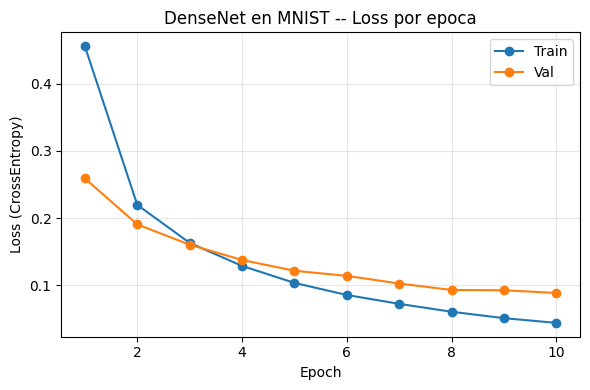

In [8]:
densenet_mnist = DenseNet()
mnist_train_loss, mnist_val_loss = train_classifier(densenet_mnist, train_loader, X_val_t, y_val_t)
plot_loss_curves(mnist_train_loss, mnist_val_loss, "DenseNet en MNIST, loss por epoca")

In [9]:
mnist_test_acc, mnist_test_preds = evaluate_accuracy(densenet_mnist, X_test_t, y_test_t)
print(f"Accuracy de prueba (MNIST, DenseNet): {mnist_test_acc:.4f}")

Accuracy de prueba (MNIST, DenseNet): 0.9742


# Parte 2, la misma red en una tarea mas dificil, Fashion MNIST

Por que reentrenar desde cero, idea del PDF. No reutilizamos los pesos aprendidos en MNIST, queremos ver que tan bien esta arquitectura aprende Fashion MNIST arrancando de cero, por sus propios meritos. Reutilizar los pesos de MNIST contestaria otra pregunta, transfer learning, no la que este experimento plantea, si el factor limitante es la arquitectura o la tarea. Lo unico que cambia entre esta parte y la anterior es el dataset. Arquitectura, hiperparametros y semilla quedan iguales.

## 2.1 cargando Fashion MNIST

El snippet que trae el PDF para esta parte tiene un error de copiar y pegar, carga mnist_train_fp y mnist_test_fp, los archivos de MNIST, en las variables fmnist_train y fmnist_test. Abajo esta corregido para cargar de verdad los archivos de Fashion MNIST.

In [10]:
fmnist_train_fp = os.getenv('FMNIST_TRAIN_FILEPATH')
fmnist_test_fp = os.getenv('FMNIST_TEST_FILEPATH')

fmnist_train = np.load(fmnist_train_fp)
fmnist_test = np.load(fmnist_test_fp)

print(f"Fashion-MNIST train dataset file path: {fmnist_train_fp}")
print(f"Fashion-MNIST test dataset file path: {fmnist_test_fp}")
print(f"fmnist_train images shape: {fmnist_train['images'].shape}, labels shape: {fmnist_train['labels'].shape}")
print(f"fmnist_test images shape: {fmnist_test['images'].shape}, labels shape: {fmnist_test['labels'].shape}")

Fashion-MNIST train dataset file path: fmnist_dataset/fmnist_train.npz
Fashion-MNIST test dataset file path: fmnist_dataset/fmnist_test.npz
fmnist_train images shape: (60000, 28, 28), labels shape: (60000,)
fmnist_test images shape: (10000, 28, 28), labels shape: (10000,)


## TAREA 2.1 y 2.2, divide, escala y reentrena desde cero

El mismo procedimiento de 1.2, split con stratify y random_state=RANDOM_SEED, escalado entre 255, tensores, pero sobre los arreglos de Fashion MNIST. Uso una instancia nueva de DenseNet, pesos recien inicializados, no los de densenet_mnist.

In [11]:
x_fmnist = fmnist_train['images'].reshape(-1, 28 * 28)
y_fmnist = fmnist_train['labels']

x_fmnist_train, x_fmnist_val, y_fmnist_train, y_fmnist_val = train_test_split(
    x_fmnist, y_fmnist,
    test_size=0.2,
    stratify=y_fmnist,
    random_state=RANDOM_SEED,
)

x_fmnist_train_scaled = x_fmnist_train / 255.0
x_fmnist_val_scaled = x_fmnist_val / 255.0

x_fmnist_test = fmnist_test['images'].reshape(-1, 28 * 28)
y_fmnist_test = fmnist_test['labels']
x_fmnist_test_scaled = x_fmnist_test / 255.0

X_fmnist_train_t = torch.from_numpy(x_fmnist_train_scaled).float()
X_fmnist_val_t = torch.from_numpy(x_fmnist_val_scaled).float()
X_fmnist_test_t = torch.from_numpy(x_fmnist_test_scaled).float()

y_fmnist_train_t = torch.from_numpy(y_fmnist_train).long()
y_fmnist_val_t = torch.from_numpy(y_fmnist_val).long()
y_fmnist_test_t = torch.from_numpy(y_fmnist_test).long()

fmnist_train_dataset = TensorDataset(X_fmnist_train_t, y_fmnist_train_t)
fmnist_dataloader_generator = torch.Generator().manual_seed(RANDOM_SEED)
fmnist_train_loader = DataLoader(
    fmnist_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=fmnist_dataloader_generator,
)

print(f"x_fmnist_train shape: {x_fmnist_train.shape}")
print(f"x_fmnist_val shape: {x_fmnist_val.shape}")

x_fmnist_train shape: (48000, 784)
x_fmnist_val shape: (12000, 784)


Epoch | Train Loss |   Val Loss


    1 |     0.6390 |     0.4779


    2 |     0.4445 |     0.3986


    3 |     0.3971 |     0.3806


    4 |     0.3679 |     0.3666


...

    6 |     0.3292 |     0.3431


    7 |     0.3173 |     0.3443


    8 |     0.3079 |     0.3436


    9 |     0.2962 |     0.3253


   10 |     0.2871 |     0.3283


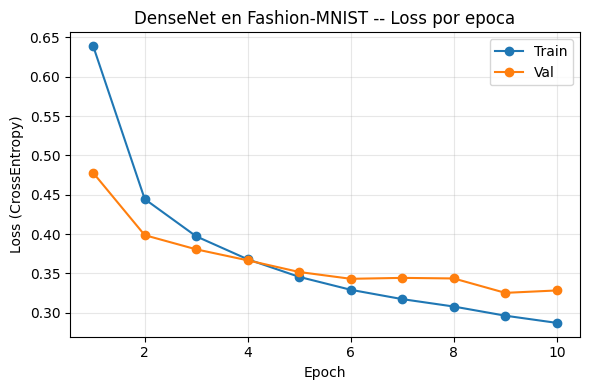

In [12]:
densenet_fmnist = DenseNet()  # instancia nueva, pesos nuevos, no reusa los de densenet_mnist
fmnist_train_loss, fmnist_val_loss = train_classifier(densenet_fmnist, fmnist_train_loader, X_fmnist_val_t, y_fmnist_val_t)
plot_loss_curves(fmnist_train_loss, fmnist_val_loss, "DenseNet en Fashion MNIST, loss por epoca")

In [13]:
fmnist_test_acc, fmnist_test_preds = evaluate_accuracy(densenet_fmnist, X_fmnist_test_t, y_fmnist_test_t)
print(f"Accuracy de prueba (Fashion-MNIST, DenseNet): {fmnist_test_acc:.4f}")

Accuracy de prueba (Fashion-MNIST, DenseNet): 0.8716


## 2.3, Parte 1 contra Parte 2

In [14]:
import pandas as pd

comparison_p1_p2 = pd.DataFrame({
    "Dataset": ["MNIST (Parte 1)", "Fashion-MNIST (Parte 2)"],
    "Precisión de Prueba (misma arquitectura)": [mnist_test_acc, fmnist_test_acc],
})
comparison_p1_p2

,Dataset,Precisión de Prueba (misma arquitectura)
0,MNIST (Parte 1),0.9742
1,Fashion-MNIST (Parte 2),0.8716


# Parte 3, mejorando la tarea dificil con una CNN

Recordatorio del PDF. Aplanar la imagen tira la estructura espacial, una capa densa trata cada pixel como una feature independiente y no sabe que dos pixeles eran vecinos. Conv2d en cambio usa conectividad local, cada salida depende solo de un vecindario chico de pixeles, y comparte parametros, el mismo filtro se aplica en toda la imagen y le da invariancia a traslacion. Ese es justo el tipo de variacion que Fashion MNIST tiene mas que MNIST.

## TAREA 3.4, construir la ConvNet

Entrada 1x28x28. Conv1, Conv2d de 1 a 16 canales, kernel 3, padding 1, mas ReLU. Pool, MaxPool2d de 2, baja a 14x14. Conv2, Conv2d de 16 a 32 canales, kernel 3, padding 1, mas ReLU. Pool, MaxPool2d de 2, baja a 7x7. Flatten, 32 por 7 por 7 da 1568. Salida, Linear de 1568 a 10, logits crudos.

La entrada no va aplanada, Conv2d espera batch, canales, alto, ancho.

In [15]:
class ConvNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2)
        self.fc_out = nn.Linear(32 * 7 * 7, 10)

    def forward(self, x):
        # x: (batch_size, 1, 28, 28)
        output = self.pool(F.relu(self.conv1(x)))
        output = self.pool(F.relu(self.conv2(output)))  # segundo pooling
        output = output.view(output.size(0), -1)        # aplana para la capa densa
        output = self.fc_out(output)
        return output

## TAREA 3.5, entrenar, evaluar y comparar

Reordeno los tensores de Fashion MNIST, que ya estan escalados, de (N, 784) a (N, 1, 28, 28) con view. Reutilizo train_classifier y evaluate_accuracy, misma funcion de perdida, mismo optimizador, misma semilla, mismo patron de ciclo que en las Partes 1 y 2.

Epoch | Train Loss |   Val Loss


    1 |     0.6273 |     0.4226


    2 |     0.3960 |     0.3540


    3 |     0.3485 |     0.3257


    4 |     0.3219 |     0.3199


...

    6 |     0.2893 |     0.2844


    7 |     0.2778 |     0.2897


    8 |     0.2691 |     0.2896


    9 |     0.2577 |     0.2736


   10 |     0.2511 |     0.2762


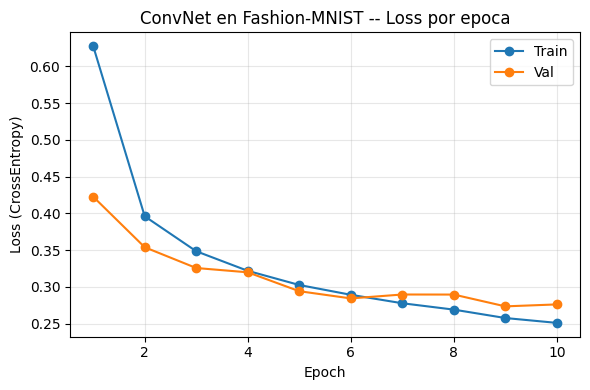

In [16]:
X_fmnist_train_img = X_fmnist_train_t.view(-1, 1, 28, 28)
X_fmnist_val_img = X_fmnist_val_t.view(-1, 1, 28, 28)
X_fmnist_test_img = X_fmnist_test_t.view(-1, 1, 28, 28)

fmnist_train_img_dataset = TensorDataset(X_fmnist_train_img, y_fmnist_train_t)
cnn_dataloader_generator = torch.Generator().manual_seed(RANDOM_SEED)
fmnist_train_img_loader = DataLoader(
    fmnist_train_img_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=cnn_dataloader_generator,
)

convnet = ConvNet()
cnn_train_loss, cnn_val_loss = train_classifier(convnet, fmnist_train_img_loader, X_fmnist_val_img, y_fmnist_val_t)
plot_loss_curves(cnn_train_loss, cnn_val_loss, "ConvNet en Fashion MNIST, loss por epoca")

In [17]:
cnn_test_acc, cnn_test_preds = evaluate_accuracy(convnet, X_fmnist_test_img, y_fmnist_test_t)
print(f"Accuracy de prueba (Fashion-MNIST, CNN): {cnn_test_acc:.4f}")

Accuracy de prueba (Fashion-MNIST, CNN): 0.8901


In [18]:
three_way_comparison = pd.DataFrame({
    "Modelo / Dataset": [
        "Densa en MNIST (Parte 1)",
        "Densa en Fashion-MNIST (Parte 2)",
        "CNN en Fashion-MNIST (Parte 3)",
    ],
    "Precisión de Prueba": [mnist_test_acc, fmnist_test_acc, cnn_test_acc],
    "Cantidad de Parámetros": [
        count_parameters(densenet_mnist),
        count_parameters(densenet_fmnist),
        count_parameters(convnet),
    ],
})
three_way_comparison

,Modelo / Dataset,Precisión de Prueba,Cantidad de Parámetros
0,Densa en MNIST (Parte 1),0.9742,101770
1,Densa en Fashion-MNIST (Parte 2),0.8716,101770
2,CNN en Fashion-MNIST (Parte 3),0.8901,20490


## 3.6 y 3.7, precision, recall, F1 por clase de la CNN en Fashion MNIST

In [19]:
FASHION_MNIST_CLASSES = [
    "Camiseta/Top", "Pantalón", "Suéter", "Vestido", "Abrigo",
    "Sandalia", "Camisa", "Tenis", "Bolso", "Botín",
]

print(classification_report(
    y_fmnist_test_t.numpy(),
    cnn_test_preds.numpy(),
    target_names=FASHION_MNIST_CLASSES,
))

              precision    recall  f1-score   support

Camiseta/Top       0.89      0.77      0.82      1000
    Pantalón       0.99      0.97      0.98      1000
      Suéter       0.75      0.90      0.82      1000
     Vestido       0.84      0.93      0.89      1000
      Abrigo       0.87      0.74      0.80      1000
    Sandalia       0.99      0.97      0.98      1000
      Camisa       0.71      0.70      0.71      1000
       Tenis       0.94      0.98      0.96      1000
       Bolso       0.98      0.97      0.98      1000
       Botín       0.98      0.96      0.97      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



# Parte 4, dropout

Agrego nn.Dropout(p) despues de aplanar y antes de fc_out. Barrido sobre p en 0.0, 0.2, 0.4 y 0.6, misma semilla y split de Fashion MNIST del resto del notebook.

In [20]:
class ConvNetDropout(nn.Module):
    def __init__(self, dropout_p):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2)
        self.dropout = nn.Dropout(p=dropout_p)
        self.fc_out = nn.Linear(32 * 7 * 7, 10)

    def forward(self, x):
        output = self.pool(F.relu(self.conv1(x)))
        output = self.pool(F.relu(self.conv2(output)))
        output = output.view(output.size(0), -1)
        output = self.dropout(output)
        output = self.fc_out(output)
        return output

In [21]:
dropout_values = [0.0, 0.2, 0.4, 0.6]
dropout_results = []
dropout_histories = {}

for p in dropout_values:
    print(f"\ndropout_p = {p}")
    model_p = ConvNetDropout(p)
    loader_generator_p = torch.Generator().manual_seed(RANDOM_SEED)
    loader_p = DataLoader(
        fmnist_train_img_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=loader_generator_p,
    )
    train_loss_p, val_loss_p = train_classifier(model_p, loader_p, X_fmnist_val_img, y_fmnist_val_t)
    acc_p, _ = evaluate_accuracy(model_p, X_fmnist_test_img, y_fmnist_test_t)

    dropout_histories[p] = (train_loss_p, val_loss_p)
    dropout_results.append({
        "dropout_p": p,
        "Precisión de Prueba": acc_p,
        "train_loss_final": train_loss_p[-1],
        "val_loss_final": val_loss_p[-1],
        "gap_val_menos_train": val_loss_p[-1] - train_loss_p[-1],
    })

dropout_df = pd.DataFrame(dropout_results)
dropout_df


--- dropout_p = 0.0 ---
Epoch | Train Loss |   Val Loss


    1 |     0.6503 |     0.4479


    2 |     0.4064 |     0.3613


    3 |     0.3545 |     0.3354


    4 |     0.3276 |     0.3187


...

    7 |     0.3652 |     0.3215


    8 |     0.3621 |     0.3077


    9 |     0.3500 |     0.2955


   10 |     0.3450 |     0.2879


,dropout_p,Precisión de Prueba,train_loss_final,val_loss_final,gap_val_menos_train
0,0.0,0.8909,0.256703,0.278699,0.021996
1,0.2,0.8990,0.273453,0.255991,-0.017462
2,0.4,0.8950,0.309758,0.275831,-0.033926
3,0.6,0.8903,0.344973,0.287908,-0.057065
